## Train enriched XGBoost 
to test whether adding demand, wind and solar forecasts improves prediction accuracy.

Compare two models using the same daily-history features:
- Price-only model: Calendar and historical electricity prices.
- Enriched model: Everything above, plus demand, wind and solar forecasts.
This makes the comparison fair. However, because historical market forecast publication times remain unverified, the enriched model is exploratory, not a leakage-safe operational backtest.

In [1]:

from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

prices = pd.read_parquet(
    ROOT / "data/processed/germany_luxembourg_analytics.parquet"
)

market = pd.read_parquet(
    ROOT / "data/processed/germany_luxembourg_market_features.parquet"
)

data = prices[["price_eur_mwh"]].join(market, how="left").sort_index()

local = data.index.tz_convert("Europe/Berlin")

data["delivery_date"] = pd.to_datetime(local.date)
data["hour"] = local.hour
data["day_of_week"] = local.day_of_week
data["month"] = local.month

daily_stats = data.groupby("delivery_date")["price_eur_mwh"].agg(
    daily_mean="mean",
    daily_min="min",
    daily_max="max",
    daily_std="std"
)

for column in daily_stats.columns:
    data[f"known_{column}"] = data["delivery_date"].map(
        daily_stats[column].shift(2)
    )

print("Dataset shape:", data.shape)
display(data.head())


Dataset shape: (26304, 12)


,price_eur_mwh,load_forecast_mw,solar_forecast_mw,wind_forecast_mw,delivery_date,hour,day_of_week,month,known_daily_mean,known_daily_min,known_daily_max,known_daily_std
timestamp_utc,,,,,,,,,,,,
2022-12-31 23:00:00+00:00,-5.17,42215.4725,0.0,39002.5525,2023-01-01,0,6,1,NaN,NaN,NaN,NaN
2023-01-01 00:00:00+00:00,-1.07,40026.9350,0.0,38805.6225,2023-01-01,1,6,1,NaN,NaN,NaN,NaN
2023-01-01 01:00:00+00:00,-1.47,38631.0300,0.0,38542.2325,2023-01-01,2,6,1,NaN,NaN,NaN,NaN
2023-01-01 02:00:00+00:00,-5.08,37588.6625,0.0,37858.9700,2023-01-01,3,6,1,NaN,NaN,NaN,NaN
2023-01-01 03:00:00+00:00,-4.49,37705.7350,0.0,37336.2900,2023-01-01,4,6,1,NaN,NaN,NaN,NaN


## 1. Recreate our enriched XGBoost model

In [3]:

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calendar + known historical prices
base_features = [
    "hour",
    "day_of_week",
    "month",
    "known_daily_mean",
    "known_daily_min",
    "known_daily_max",
    "known_daily_std",
]

# Add market forecasts
market_features = [
    "load_forecast_mw",
    "solar_forecast_mw",
    "wind_forecast_mw",
]

enriched_features = base_features + market_features

# Keep identical rows for both models
experiment = data.dropna(
    subset=enriched_features + ["price_eur_mwh"]
).copy()

# Chronological split using German delivery dates
train = experiment[
    experiment["delivery_date"].dt.year == 2023
]

validation = experiment[
    experiment["delivery_date"].dt.year == 2024
]

print("Train:", len(train))
print("Validation:", len(validation))


def evaluate_model(features, name):
    model = XGBRegressor(
        n_estimators=500,
        max_depth=4,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
    )

    model.fit(
        train[features],
        train["price_eur_mwh"]
    )

    predictions = model.predict(
        validation[features]
    )

    mae = mean_absolute_error(
        validation["price_eur_mwh"],
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            validation["price_eur_mwh"],
            predictions
        )
    )

    print(f"\n{name}")
    print(f"MAE:  {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")

    return model, predictions


base_model, base_predictions = evaluate_model(
    base_features, "Price-only XGBoost"
)

enriched_model, enriched_predictions = evaluate_model(
    enriched_features, "Enriched XGBoost"
)


Train: 8711
Validation: 8783

Price-only XGBoost
MAE:  30.282
RMSE: 45.792

Enriched XGBoost
MAE:  24.327
RMSE: 37.929


## 2. Error Analysis by Electricity Price Category

Evaluate how well the enriched XGBoost model predicts normal prices, negative prices, and extreme price spikes.

In [4]:

# Compare actual prices against predictions
results = validation[["price_eur_mwh"]].copy()

results["predicted_price"] = enriched_predictions

results["absolute_error"] = abs(
    results["price_eur_mwh"] - results["predicted_price"]
)

# Categorize actual electricity prices
bins = [-np.inf, 0, 50, 100, 150, np.inf]

labels = [
    "Negative",
    "0–50",
    "50–100",
    "100–150",
    "Above 150"
]

results["price_category"] = pd.cut(
    results["price_eur_mwh"],
    bins=bins,
    labels=labels,
    right=False
)

# Calculate MAE for each category
category_analysis = (
    results.groupby("price_category", observed=True)
    .agg(
        hours=("absolute_error", "count"),
        mae=("absolute_error", "mean")
    )
)

display(category_analysis.round(2))


,hours,mae
price_category,,
Negative,457,23.36
0–50,1414,25.68
50–100,4604,23.68
100–150,1944,17.05
Above 150,364,67.29


The enriched XGBoost model handles normal electricity prices reasonably well, but struggles with extreme price spikes.

## 3. Feature importance analysis
Before changing the model, let's understand which features it relies on.

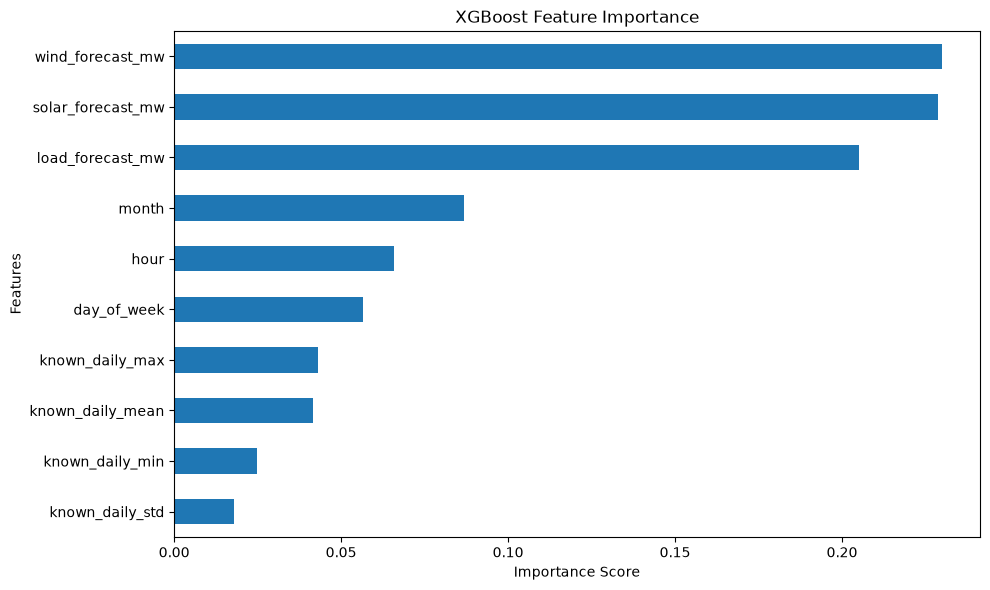

In [5]:

import matplotlib.pyplot as plt
import pandas as pd

importance = pd.Series(
    enriched_model.feature_importances_,
    index=enriched_features
).sort_values()

plt.figure(figsize=(10, 6))
importance.plot(kind="barh")

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


XGBoost model is relying heavily on wind, solar, and electricity demand forecasts, rather than just historical electricity prices.
Instead of immediately switching algorithms, let's give XGBoost more meaningful information about electricity supply and demand.

We'll create three additional features:
- Residual load: Electricity demand minus forecast wind and solar generation.
- Renewable share: Wind and solar generation divided by forecast demand.
- Wind-to-load ratio: How much forecast demand could be covered by wind generation.

## 4. Energy Market Feature Engineering  
We're testing whether adding residual load, renewable share, and wind-to-load ratio improves forecasting accuracy.

In [7]:

# Work on a copy of our existing experiment
engineered = experiment.copy()

# Demand remaining after wind and solar generation
engineered["residual_load_mw"] = (
    engineered["load_forecast_mw"]
    - engineered["wind_forecast_mw"]
    - engineered["solar_forecast_mw"]
)

# Renewable generation relative to electricity demand
engineered["renewable_share"] = (
    engineered["wind_forecast_mw"]
    + engineered["solar_forecast_mw"]
) / engineered["load_forecast_mw"].replace(0, np.nan)

# Wind generation relative to demand
engineered["wind_load_ratio"] = (
    engineered["wind_forecast_mw"]
    / engineered["load_forecast_mw"].replace(0, np.nan)
)

new_features = [
    "residual_load_mw",
    "renewable_share",
    "wind_load_ratio"
]

engineered_features = enriched_features + new_features

engineered = engineered.replace(
    [np.inf, -np.inf], np.nan
).dropna(subset=engineered_features)

train_eng = engineered[
    engineered["delivery_date"].dt.year == 2023
]

validation_eng = engineered[
    engineered["delivery_date"].dt.year == 2024
]

print("Train:", len(train_eng))
print("Validation:", len(validation_eng))

display(engineered[new_features].head())


Train: 8711
Validation: 8783


,residual_load_mw,renewable_share,wind_load_ratio
timestamp_utc,,,
2023-01-02 23:00:00+00:00,25560.0800,0.452661,0.452661
2023-01-03 00:00:00+00:00,25430.9175,0.437237,0.437237
2023-01-03 01:00:00+00:00,25900.2325,0.415887,0.415887
2023-01-03 02:00:00+00:00,27100.4675,0.389370,0.389370
2023-01-03 03:00:00+00:00,29933.8125,0.350642,0.350642


Train the engineered XGBoost model

In [8]:

engineered_model = XGBRegressor(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

engineered_model.fit(
    train_eng[engineered_features],
    train_eng["price_eur_mwh"]
)

engineered_predictions = engineered_model.predict(
    validation_eng[engineered_features]
)

engineered_mae = mean_absolute_error(
    validation_eng["price_eur_mwh"],
    engineered_predictions
)

engineered_rmse = np.sqrt(
    mean_squared_error(
        validation_eng["price_eur_mwh"],
        engineered_predictions
    )
)

print("Previous enriched MAE: 24.327")
print(f"Engineered MAE: {engineered_mae:.3f}")

print("\nPrevious enriched RMSE: 37.929")
print(f"Engineered RMSE: {engineered_rmse:.3f}")


Previous enriched MAE: 24.327
Engineered MAE: 24.315

Previous enriched RMSE: 37.929
Engineered RMSE: 37.831


Adding wind, solar and load forecasts gave us a substantial improvement over the price-only model.  
Adding residual load and renewable ratios provided almost no additional benefit.  
Our biggest remaining weakness is predicting extreme electricity prices above €150/MWh.  

Keep the original enriched XGBoost as our simpler baseline, and retain the engineered version as an experiment.
Rather than adding more features randomly, let's investigate whether the engineered model actually improved spike prediction.

## Compare errors during price spikes

In [9]:

comparison = validation_eng[["price_eur_mwh"]].copy()

comparison["enriched_prediction"] = enriched_model.predict(
    validation_eng[enriched_features]
)

comparison["engineered_prediction"] = engineered_predictions

comparison["enriched_error"] = abs(
    comparison["price_eur_mwh"] -
    comparison["enriched_prediction"]
)

comparison["engineered_error"] = abs(
    comparison["price_eur_mwh"] -
    comparison["engineered_prediction"]
)

comparison["category"] = pd.cut(
    comparison["price_eur_mwh"],
    bins=[-np.inf, 0, 50, 100, 150, np.inf],
    labels=["Negative", "0–50", "50–100", "100–150", "Above 150"],
    right=False
)

category_comparison = comparison.groupby(
    "category", observed=True
)[["enriched_error", "engineered_error"]].mean()

category_comparison.columns = [
    "Enriched MAE",
    "Engineered MAE"
]

display(category_comparison.round(2))


,Enriched MAE,Engineered MAE
category,,
Negative,23.36,17.30
0–50,25.68,24.44
50–100,23.68,24.26
100–150,17.05,18.25
Above 150,67.29,65.72


Our engineered features have significantly improved negative-price predictions.

The engineered model is better at predicting negative electricity prices, even though its overall MAE barely changed.  
That matters because negative prices are an important phenomenon in European electricity markets.

Retain both models for now:
- Enriched XGBoost: Simpler model with strong overall performance.
- Engineered XGBoost: Better negative-price performance, with almost identical overall MAE.  

Before choosing the final model, we should evaluate both on 2025 data.

This is important because we have been making decisions based on 2024 validation results. Testing on another year will show whether the improvements generalize.

In [11]:

# Evaluate the existing 2023-trained models on 2025
test_2025 = engineered[
    engineered["delivery_date"].dt.year == 2025
].copy()

y_test = test_2025["price_eur_mwh"]

pred_enriched = enriched_model.predict(
    test_2025[enriched_features]
)

pred_engineered = engineered_model.predict(
    test_2025[engineered_features]
)

for name, predictions in [
    ("Enriched XGBoost", pred_enriched),
    ("Engineered XGBoost", pred_engineered)
]:
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    print(f"\n{name}")
    print(f"MAE:  {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")



Enriched XGBoost
MAE:  15.882
RMSE: 24.459

Engineered XGBoost
MAE:  14.979
RMSE: 23.340


Market forecasts are valuable. Wind, solar and electricity demand features substantially improved our 2024 validation results.



Feature engineering appears useful. Residual load and renewable ratios improved 2025 MAE by approximately 5.7%.



The model generalizes reasonably well across years in this retrospective experiment. Both models were trained on 2023 and evaluated on 2025.

## 5. Final Model Training and Export

So far, our engineered XGBoost model was trained on 2023. Now we'll retrain it using both 2023 and 2024 to give it more historical data.

In [12]:

from pathlib import Path
import joblib
import json
from xgboost import XGBRegressor

# Train using 2023 and 2024
final_train = engineered[
    engineered["delivery_date"].dt.year.isin([2023, 2024])
].copy()

X_final = final_train[engineered_features]
y_final = final_train["price_eur_mwh"]

final_model = XGBRegressor(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_final, y_final)

# Create models directory
MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save model
model_path = MODEL_DIR / "enriched_xgboost.joblib"
joblib.dump(final_model, model_path)

# Save feature names in exact training order
feature_path = MODEL_DIR / "enriched_features.json"

with open(feature_path, "w") as f:
    json.dump(engineered_features, f, indent=2)

print("Training rows:", len(final_train))
print("Model saved:", model_path)
print("Features saved:", feature_path)
print("Feature count:", len(engineered_features))


Training rows: 17494
Model saved: c:\Users\User\OneDrive - Manipal Education (MENA) FZ LLC\Desktop\EU Market monitor\models\enriched_xgboost.joblib
Features saved: c:\Users\User\OneDrive - Manipal Education (MENA) FZ LLC\Desktop\EU Market monitor\models\enriched_features.json
Feature count: 13
